## QQ Plot

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = sns.load_dataset('iris')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

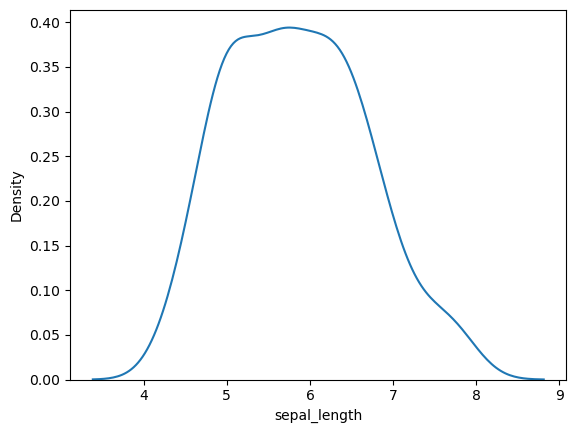

In [4]:
sns.kdeplot(df['sepal_length'])

In [5]:
temp = sorted(df['sepal_length'].tolist())

In [6]:
y_quant = []
for i in range(1,101):
    y_quant.append(np.percentile(temp, i))

In [7]:
sample = np.random.normal(loc=0, scale=1, size=1000)

In [8]:
x_quant = []
for i in range(1,101):
    x_quant.append(np.percentile(sample, i))

<Axes: >

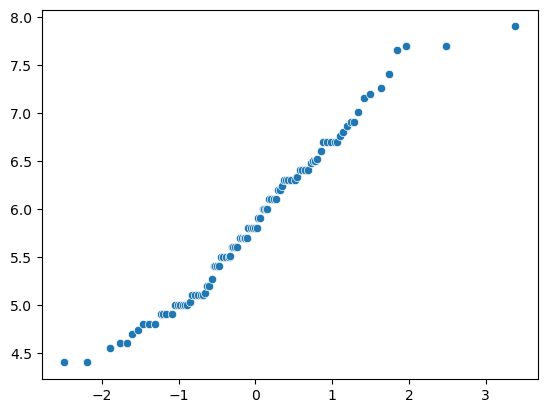

In [10]:
sns.scatterplot(x = x_quant, y = y_quant)

#### Using Statsmodel

In [14]:
import statsmodels.api as sm

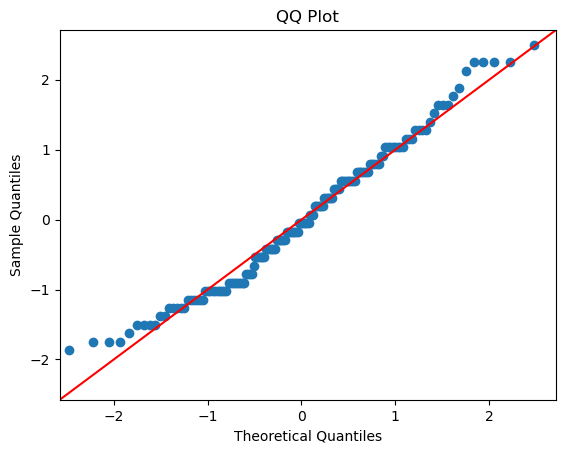

In [15]:
# Create a QQ Plot of the two sets of data

fig = sm.qqplot(df['sepal_length'], line='45', fit=True)

# Add a title and labels to the plot
plt.title('QQ Plot')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')

# Show the plot
plt.show()

### Does QQ Plot only Detect Normal Distribution?

In [16]:
# Normal Distribution
# Uniform Distribution
# Pareto
# Log Normal

In [17]:
import scipy.stats as stats

In [18]:
# Generate a set of random data

x = np.random.uniform(low=0, high=1, size=1000)

(array([103., 109.,  98.,  81., 102.,  97., 114.,  98.,  99.,  99.]),
 array([4.72746281e-04, 1.00368047e-01, 2.00263347e-01, 3.00158647e-01,
        4.00053947e-01, 4.99949247e-01, 5.99844548e-01, 6.99739848e-01,
        7.99635148e-01, 8.99530448e-01, 9.99425749e-01]),
 <BarContainer object of 10 artists>)

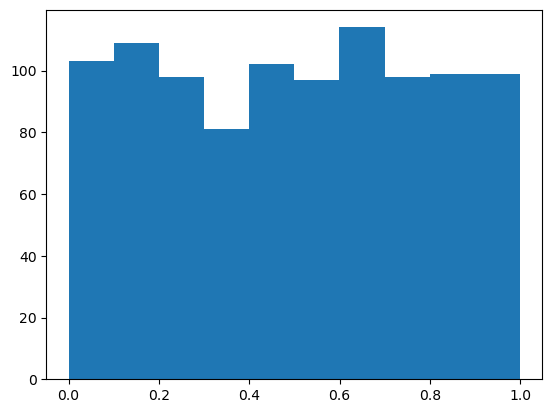

In [19]:
plt.hist(x)

In [21]:
# Fit a uniform distribution to the data

params = stats.uniform.fit(x)
dist = stats.uniform(loc=params[0], scale=params[1])

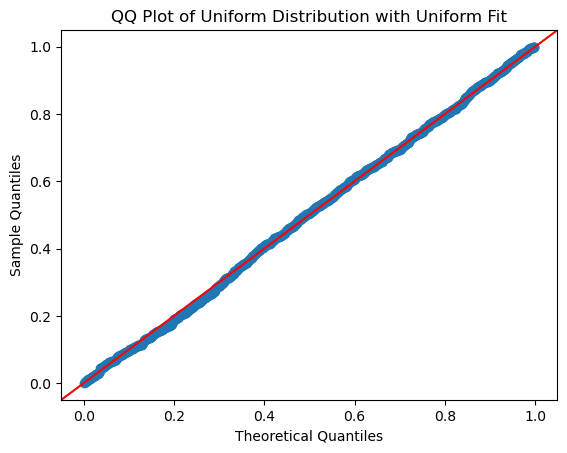

In [23]:
# Create a QQ Plot of the data using the uniform distribution

fig = sm.qqplot(x, dist=dist, line='45')

plt.title('QQ Plot of Uniform Distribution with Uniform Fit')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')

plt.show()

## Pareto Distribution

In [28]:
# Define the parameter of the pareto distribution 

alpha = 3
xm = 1

In [29]:
# Create an array of x values
x = np.linspace(0.1, 10, 1000)

# Calculate the y values of the Pareto distribution
y = alpha * (xm**alpha) / (x**(alpha+1))

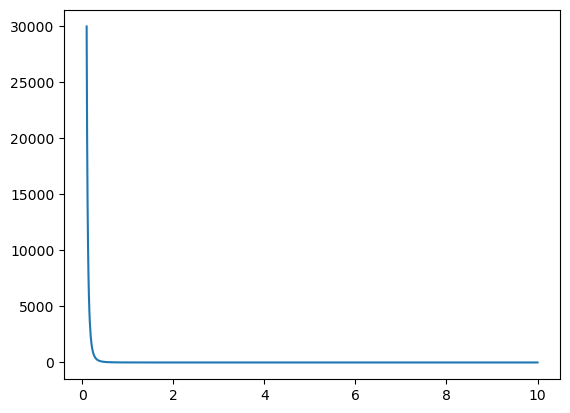

In [30]:
plt.plot(x,y)

### Log-Log Plot

Text(0.5, 1.0, 'Pareto Distribution')

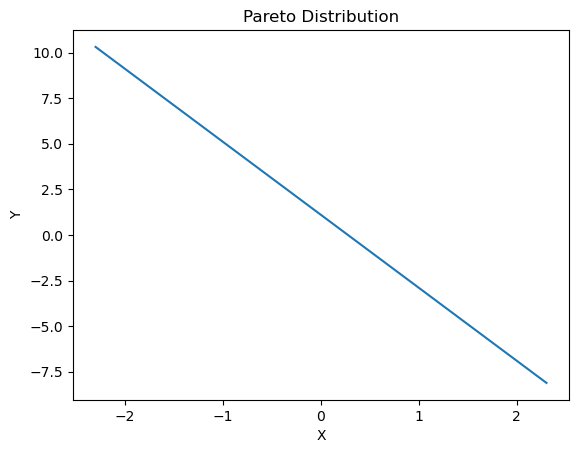

In [31]:
# Create the log-log plot

plt.plot(np.log(x), np.log(y))
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Pareto Distribution')

### QQ Plot

In [32]:
# Define the parameter of the pareto distribution

alpha = 2
xm = 1

x = stats.pareto.rvs(b=alpha, scale=xm, size=1000)

(array([974.,  17.,   4.,   2.,   1.,   0.,   1.,   0.,   0.,   1.]),
 array([ 1.00041865,  6.00161595, 11.00281325, 16.00401056, 21.00520786,
        26.00640517, 31.00760247, 36.00879977, 41.00999708, 46.01119438,
        51.01239169]),
 <BarContainer object of 10 artists>)

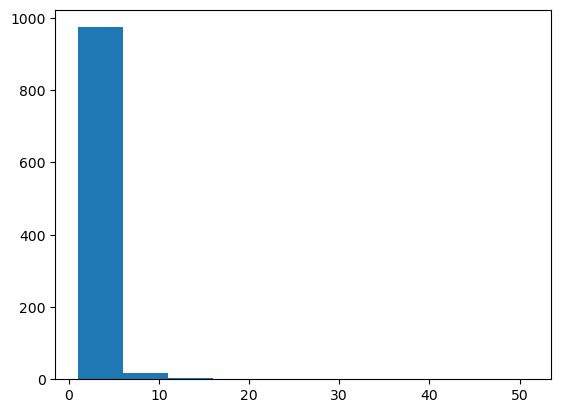

In [33]:
plt.hist(x)

In [34]:
# Fit a Pareto distribution to data
params = stats.pareto.fit(x, floc=0)

# Create a Pareto distribution object with the fitted parameters
dist = stats.pareto(b=params[0], scale=params[2])

Text(0, 0.5, 'Sample Quantiles')

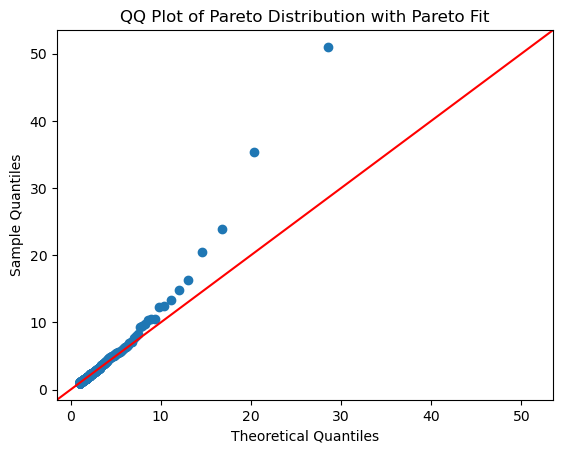

In [35]:
# Create a QQ Plot of the data using the pareto distribution

fig = sm.qqplot(x, dist=dist, line='45')
plt.title('QQ Plot of Pareto Distribution with Pareto Fit')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')